# Algoritmos evolutivos: escapar de un laberinto con un algoritmo genético

En este taller construiremos un algoritmo genético sencillo que evoluciona secuencias de movimientos para encontrar la salida de un laberinto.

## Objetivos

Al terminar podrás identificar los componentes principales de un algoritmo genético:

- **Individuo:** una posible solución.
- **Población:** conjunto de soluciones candidatas.
- **Fitness:** medida de qué tan buena es una solución.
- **Selección:** elección de individuos para reproducirse.
- **Crossover:** combinación de dos soluciones.
- **Mutación:** cambios aleatorios que mantienen diversidad.
- **Generación:** una iteración completa del proceso evolutivo.

> El objetivo del laberinto es didáctico. Para encontrar caminos en un laberinto conocido, algoritmos como BFS o A* son normalmente más apropiados que un algoritmo genético.

## 1. Preparación

Usaremos únicamente herramientas básicas de Python y `matplotlib`.

La semilla aleatoria permite repetir el experimento y obtener el mismo resultado.

In [7]:
import random
from collections import deque

import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)

## 2. El laberinto

Representaremos el laberinto como una matriz:

- `1` = pared
- `0` = espacio transitable

El agente comienza en `START` y debe alcanzar `GOAL`.

In [8]:
maze = [
    [1,1,1,1,1,1,1,1,1,1],
    [1,0,0,0,1,0,0,0,0,1],
    [1,0,1,0,1,0,1,1,0,1],
    [1,0,1,0,0,0,0,1,0,1],
    [1,0,1,1,1,1,0,1,0,1],
    [1,0,0,0,0,1,0,0,0,1],
    [1,1,1,1,0,1,1,1,0,1],
    [1,0,0,0,0,0,0,1,0,1],
    [1,0,1,1,1,1,0,0,0,1],
    [1,1,1,1,1,1,1,1,1,1],
]

START = (1, 1)
GOAL = (8, 8)

ROWS = len(maze)
COLS = len(maze[0])

MOVES = {
    "U": (-1, 0),  # arriba
    "D": (1, 0),   # abajo
    "L": (0, -1),  # izquierda
    "R": (0, 1),   # derecha
}

## 3. Visualización del laberinto

Antes de aplicar el algoritmo genético, veamos el problema que queremos resolver.

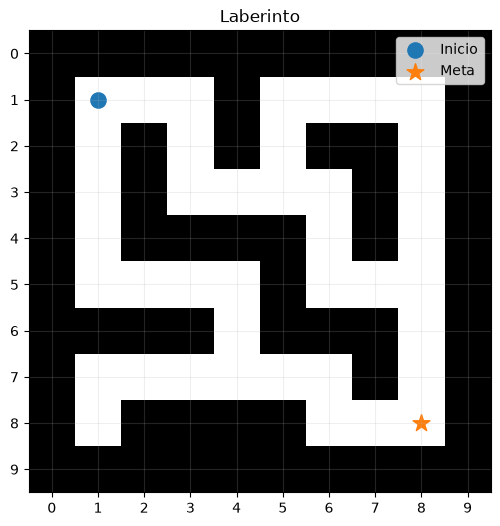

In [9]:
def plot_maze(path=None, title="Laberinto"):
    plt.figure(figsize=(6, 6))
    plt.imshow(maze, cmap="gray_r")

    # Inicio y meta
    plt.scatter(START[1], START[0], s=120, marker="o", label="Inicio")
    plt.scatter(GOAL[1], GOAL[0], s=160, marker="*", label="Meta")

    # Camino recorrido
    if path:
        ys = [position[0] for position in path]
        xs = [position[1] for position in path]
        plt.plot(xs, ys, linewidth=2, label="Recorrido")

    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.grid(alpha=0.2)
    plt.title(title)
    plt.legend()
    plt.show()


plot_maze()

## 4. Representación de un individuo

Cada individuo será una secuencia de movimientos de longitud fija.

Por ejemplo:

`["R", "R", "D", "L", "D", ...]`

Cada movimiento funciona como un **gen**, y la secuencia completa funciona como el **cromosoma**.

In [10]:
CHROMOSOME_LENGTH = 20


def create_individual():
    return [
        random.choice(list(MOVES.keys()))
        for _ in range(CHROMOSOME_LENGTH)
    ]


example_individual = create_individual()
example_individual

['U',
 'U',
 'L',
 'D',
 'D',
 'D',
 'U',
 'U',
 'R',
 'U',
 'U',
 'U',
 'D',
 'D',
 'U',
 'D',
 'R',
 'D',
 'R',
 'L']

## 5. Simular un individuo

Para evaluar una solución necesitamos ejecutar sus movimientos.

Si un movimiento intenta atravesar una pared, el agente permanece en la misma posición y contamos ese intento como un movimiento inválido.

La simulación termina inmediatamente si el individuo llega a la meta.

In [11]:
def simulate_individual(individual):
    row, col = START
    path = [START]
    invalid_moves = 0

    for step, move in enumerate(individual, start=1):
        dr, dc = MOVES[move]
        new_row = row + dr
        new_col = col + dc

        if (
            0 <= new_row < ROWS
            and 0 <= new_col < COLS
            and maze[new_row][new_col] == 0
        ):
            row, col = new_row, new_col
            path.append((row, col))
        else:
            invalid_moves += 1

        if (row, col) == GOAL:
            return {
                "reached_goal": True,
                "position": (row, col),
                "path": path,
                "invalid_moves": invalid_moves,
                "steps_used": step,
            }

    return {
        "reached_goal": False,
        "position": (row, col),
        "path": path,
        "invalid_moves": invalid_moves,
        "steps_used": CHROMOSOME_LENGTH,
    }


simulate_individual(example_individual)

{'reached_goal': False,
 'position': (4, 1),
 'path': [(1, 1),
  (2, 1),
  (3, 1),
  (4, 1),
  (3, 1),
  (2, 1),
  (1, 1),
  (2, 1),
  (3, 1),
  (2, 1),
  (3, 1),
  (4, 1)],
 'invalid_moves': 9,
 'steps_used': 20}

## 6. Distancia a la meta con BFS

*   List item
*   List item



El algoritmo genético necesita una señal que indique si una solución está mejorando.

Usaremos **BFS (Breadth-First Search)** una sola vez para calcular la distancia real desde cada celda transitable hasta la meta.

BFS **no es el algoritmo que estamos usando para generar la solución genética**. Aquí funciona únicamente como parte de la función de evaluación: nos permite saber si un individuo consiguió acercarse realmente a la salida teniendo en cuenta las paredes.

In [12]:
def calculate_bfs_distances():
    distances = [
        [None for _ in range(COLS)]
        for _ in range(ROWS)
    ]

    queue = deque([GOAL])
    distances[GOAL[0]][GOAL[1]] = 0

    while queue:
        row, col = queue.popleft()

        for dr, dc in MOVES.values():
            new_row = row + dr
            new_col = col + dc

            if (
                0 <= new_row < ROWS
                and 0 <= new_col < COLS
                and maze[new_row][new_col] == 0
                and distances[new_row][new_col] is None
            ):
                distances[new_row][new_col] = distances[row][col] + 1
                queue.append((new_row, new_col))

    return distances


BFS_DISTANCES = calculate_bfs_distances()
START_DISTANCE = BFS_DISTANCES[START[0]][START[1]]

print("Distancia mínima desde el inicio hasta la meta:", START_DISTANCE)

Distancia mínima desde el inicio hasta la meta: 14


## 7. Función de fitness

El `fitness` mide qué tan buena es una solución.

Para individuos que todavía no llegan a la meta:

1. premiamos el **progreso** conseguido;
2. penalizamos movimientos inválidos.

Si un individuo llega a la meta recibe un bono grande. Además, obtiene un pequeño premio adicional si utiliza menos movimientos.

Esto provoca que primero se favorezcan individuos que se acercan a la meta y, una vez encontrada una solución, se favorezcan rutas más cortas.

In [13]:
INVALID_MOVE_PENALTY = 1
GOAL_BONUS = 1000


def calculate_fitness(individual):
    result = simulate_individual(individual)

    # Mejor distancia a la meta alcanzada durante todo el recorrido.
    best_distance = min(
        BFS_DISTANCES[row][col]
        for row, col in result["path"]
    )

    if result["reached_goal"]:
        unused_steps = CHROMOSOME_LENGTH - result["steps_used"]

        return (
            GOAL_BONUS
            + unused_steps * 5
            - result["invalid_moves"] * INVALID_MOVE_PENALTY
        )

    progress = START_DISTANCE - best_distance

    return (
        progress * 10
        - result["invalid_moves"] * INVALID_MOVE_PENALTY
    )


calculate_fitness(example_individual)

21

## 8. Crear la población

Una población es simplemente un conjunto de individuos.

Comenzamos con soluciones aleatorias. Después, el proceso evolutivo irá favoreciendo combinaciones de movimientos con mejor fitness.

In [14]:
POPULATION_SIZE = 60


def create_population():
    return [
        create_individual()
        for _ in range(POPULATION_SIZE)
    ]


population = create_population()

print("Individuos:", len(population))
print("Ejemplo:", population[0])

Individuos: 60
Ejemplo: ['U', 'D', 'R', 'L', 'L', 'D', 'D', 'L', 'U', 'U', 'R', 'U', 'L', 'L', 'L', 'U', 'R', 'U', 'R', 'U']


## 9. Selección por torneo

Para reproducirse no elegiremos individuos completamente al azar.

En la **selección por torneo** tomamos unos pocos individuos aleatorios y elegimos al que tenga mejor fitness.

Esto favorece las soluciones más prometedoras sin eliminar totalmente la diversidad.

In [15]:
TOURNAMENT_SIZE = 3


def tournament_selection(population, fitness_values):
    candidate_indices = random.sample(
        range(len(population)),
        TOURNAMENT_SIZE
    )

    winner_index = max(
        candidate_indices,
        key=lambda index: fitness_values[index]
    )

    return population[winner_index]

## 10. Crossover

El crossover combina información de dos padres.

Usaremos **crossover de un punto**:

1. elegimos una posición aleatoria;
2. tomamos la primera parte de un padre;
3. tomamos la segunda parte del otro.

El resultado son dos nuevos individuos.

In [16]:
def crossover(parent1, parent2):
    point = random.randint(1, CHROMOSOME_LENGTH - 1)

    child1 = parent1[:point] + parent2[point:]
    child2 = parent2[:point] + parent1[point:]

    return child1, child2

## 11. Mutación

La mutación cambia aleatoriamente algunos genes.

Su función es introducir diversidad y permitir explorar nuevas soluciones que quizá no existían en la población actual.

Una tasa demasiado baja puede reducir la exploración. Una tasa demasiado alta puede destruir combinaciones útiles.

In [17]:
MUTATION_RATE = 0.05


def mutate(individual):
    mutated = individual.copy()

    for index, current_move in enumerate(mutated):
        if random.random() < MUTATION_RATE:
            alternatives = [
                move
                for move in MOVES
                if move != current_move
            ]
            mutated[index] = random.choice(alternatives)

    return mutated

## 12. Evolución

Ahora combinamos todas las piezas.

En cada generación:

1. evaluamos el fitness;
2. conservamos algunos de los mejores individuos (**elitismo**);
3. seleccionamos padres;
4. aplicamos crossover;
5. aplicamos mutación;
6. formamos una nueva población.

El proceso termina si encontramos la salida o si alcanzamos el número máximo de generaciones.

In [18]:
GENERATIONS = 80
ELITE_SIZE = 4


def evolve(verbose=True):
    population = create_population()

    best_fitness_history = []
    mean_fitness_history = []

    best_individual = None
    best_fitness = float("-inf")

    for generation in range(GENERATIONS):
        fitness_values = [
            calculate_fitness(individual)
            for individual in population
        ]

        # Ordenamos índices de mejor a peor.
        ranked_indices = sorted(
            range(len(population)),
            key=lambda index: fitness_values[index],
            reverse=True,
        )

        generation_best_index = ranked_indices[0]
        generation_best_fitness = fitness_values[generation_best_index]

        if generation_best_fitness > best_fitness:
            best_fitness = generation_best_fitness
            best_individual = population[generation_best_index].copy()

        best_fitness_history.append(best_fitness)
        mean_fitness_history.append(
            sum(fitness_values) / len(fitness_values)
        )

        best_result = simulate_individual(best_individual)

        if verbose:
            print(
                f"Generación {generation:02d} | "
                f"Mejor fitness: {best_fitness:6.1f} | "
                f"Meta: {'sí' if best_result['reached_goal'] else 'no'}"
            )

        if best_result["reached_goal"]:
            return {
                "best_individual": best_individual,
                "best_fitness": best_fitness,
                "best_fitness_history": best_fitness_history,
                "mean_fitness_history": mean_fitness_history,
                "generations_used": generation + 1,
            }

        # Elitismo: conservar directamente los mejores.
        new_population = [
            population[index].copy()
            for index in ranked_indices[:ELITE_SIZE]
        ]

        # Crear descendencia hasta completar la población.
        while len(new_population) < POPULATION_SIZE:
            parent1 = tournament_selection(
                population,
                fitness_values
            )
            parent2 = tournament_selection(
                population,
                fitness_values
            )

            child1, child2 = crossover(parent1, parent2)

            new_population.append(mutate(child1))

            if len(new_population) < POPULATION_SIZE:
                new_population.append(mutate(child2))

        population = new_population

    return {
        "best_individual": best_individual,
        "best_fitness": best_fitness,
        "best_fitness_history": best_fitness_history,
        "mean_fitness_history": mean_fitness_history,
        "generations_used": GENERATIONS,
    }

## 13. Ejecutar el algoritmo

Restablecemos la semilla para que el resultado del taller sea reproducible.

In [19]:
random.seed(SEED)

result = evolve(verbose=True)

best_individual = result["best_individual"]
best_result = simulate_individual(best_individual)

print("\n--- Resultado ---")
print("Llegó a la meta:", best_result["reached_goal"])
print("Generaciones utilizadas:", result["generations_used"])
print("Movimientos utilizados:", best_result["steps_used"])
print("Fitness:", result["best_fitness"])
print("Cromosoma:", best_individual)

Generación 00 | Mejor fitness:   65.0 | Meta: no
Generación 01 | Mejor fitness:   73.0 | Meta: no
Generación 02 | Mejor fitness:   95.0 | Meta: no
Generación 03 | Mejor fitness:  101.0 | Meta: no
Generación 04 | Mejor fitness:  101.0 | Meta: no
Generación 05 | Mejor fitness:  103.0 | Meta: no
Generación 06 | Mejor fitness:  106.0 | Meta: no
Generación 07 | Mejor fitness:  114.0 | Meta: no
Generación 08 | Mejor fitness:  114.0 | Meta: no
Generación 09 | Mejor fitness:  114.0 | Meta: no
Generación 10 | Mejor fitness:  124.0 | Meta: no
Generación 11 | Mejor fitness:  124.0 | Meta: no
Generación 12 | Mejor fitness:  996.0 | Meta: sí

--- Resultado ---
Llegó a la meta: True
Generaciones utilizadas: 13
Movimientos utilizados: 20
Fitness: 996
Cromosoma: ['D', 'D', 'U', 'D', 'R', 'D', 'D', 'R', 'U', 'U', 'R', 'R', 'U', 'D', 'D', 'R', 'R', 'D', 'R', 'R']


## 14. Visualizar la mejor solución

Ahora podemos observar el recorrido del mejor individuo encontrado.

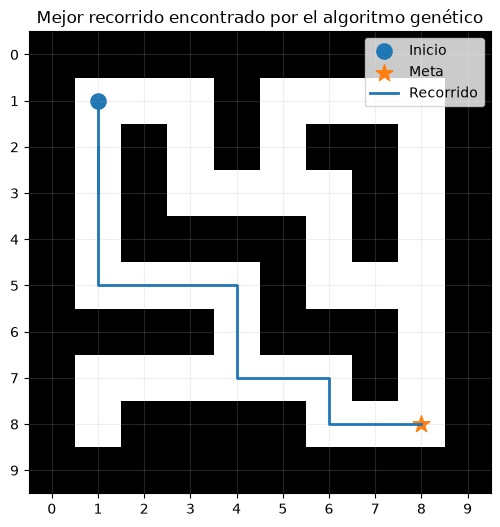

In [20]:
plot_maze(
    path=best_result["path"],
    title="Mejor recorrido encontrado por el algoritmo genético",
)

## 15. Evolución del fitness

La gráfica permite observar cómo cambia la población a lo largo de las generaciones.

- **Mejor fitness:** mejor solución encontrada hasta ese momento.
- **Fitness promedio:** rendimiento medio de la población actual.

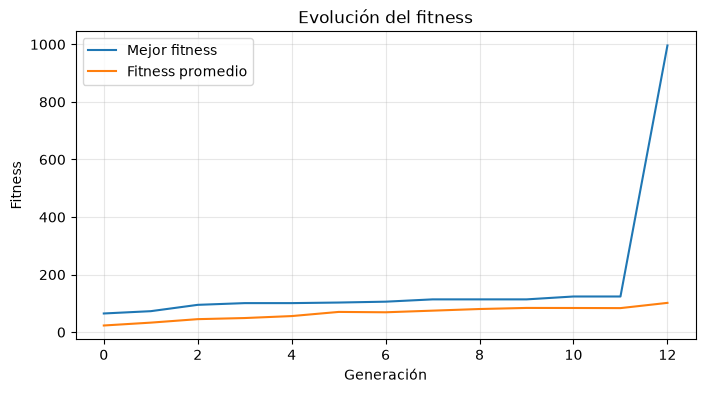

In [21]:
plt.figure(figsize=(8, 4))

plt.plot(
    result["best_fitness_history"],
    label="Mejor fitness"
)

plt.plot(
    result["mean_fitness_history"],
    label="Fitness promedio"
)

plt.xlabel("Generación")
plt.ylabel("Fitness")
plt.title("Evolución del fitness")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Conclusiones

En este ejemplo vimos los elementos esenciales de un algoritmo genético:

1. representamos una solución como un cromosoma;
2. creamos una población inicial aleatoria;
3. evaluamos cada individuo mediante una función de fitness;
4. seleccionamos individuos con mejor desempeño;
5. generamos descendencia mediante crossover y mutación;
6. repetimos el proceso durante varias generaciones.

El algoritmo no conoce directamente la secuencia correcta de movimientos. La solución aparece gradualmente porque las operaciones evolutivas favorecen y recombinan individuos con mejor desempeño.

## Limitación importante

Un algoritmo genético no es la herramienta más eficiente para resolver un laberinto conocido. Algoritmos de búsqueda como BFS o A* pueden encontrar rutas de forma directa y con garantías más claras.

Aquí utilizamos el laberinto porque permite observar de forma sencilla cómo una población de soluciones puede mejorar mediante **selección, crossover y mutación**.